# Book Market Analytics – Books to Scrape
**Data Science 500 Assignment**  
Richfield Graduate Institution

---

**Project Objective**  
Build an end-to-end data science solution that scrapes the Books to Scrape catalogue, cleans and explores the data, visualises pricing and rating patterns, and develops a linear regression model to estimate book prices.

**Workflow**
1. Data Acquisition (Web Scraping with BeautifulSoup)
2. Data Cleaning & Preparation
3. Exploratory Data Analysis & Visualisation
4. Predictive Modelling (Linear Regression)
5. Interpretation, Insights & Recommendations

## 1. Data Acquisition

In [1]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

# Modelling
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Display settings
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print('Libraries loaded successfully.')

Libraries loaded successfully.


### 1.1 Scraping Strategy

The full catalogue on [books.toscrape.com](https://books.toscrape.com) contains **1 000 books** across 50 pages (20 books per page).

We scrape:
- Listing pages for title, price, star rating and availability status
- Individual product pages for genre, UPC, tax, number of reviews, stock quantity and description

The scraper (`scrape_books.py`) uses **BeautifulSoup** + `requests` and was executed to collect **300 books** (15 pages) – well above the minimum requirement of ~100–200 products.  
The raw data has been saved to `data/books_raw.csv` for reproducibility.

In [2]:
# Load the previously scraped raw dataset
raw = pd.read_csv('data/books_raw.csv')
print(f'Raw dataset shape: {raw.shape}')
print(f'Columns: {list(raw.columns)}')
raw.head()

Raw dataset shape: (300, 16)
Columns: ['title', 'price_str', 'rating_word', 'availability_status', 'availability_qty', 'book_url', 'upc', 'product_type', 'price_excl_tax', 'price_incl_tax', 'tax', 'num_reviews', 'genre', 'description', 'detail_status', 'detail_qty']


,title,price_str,rating_word,availability_status,availability_qty,book_url,upc,product_type,price_excl_tax,price_incl_tax,tax,num_reviews,genre,description,detail_status,detail_qty
0,A Light in the Attic,£51.77,Three,In stock,NaN,https://books.toscrape.com/catalogue/a-light-i...,a897fe39b1053632,Books,£51.77,£51.77,£0.00,0,Poetry,It's hard to imagine a world without A Light i...,In stock,22
1,Tipping the Velvet,£53.74,One,In stock,NaN,https://books.toscrape.com/catalogue/tipping-t...,90fa61229261140a,Books,£53.74,£53.74,£0.00,0,Historical Fiction,"""Erotic and absorbing...Written with starling ...",In stock,20
2,Soumission,£50.10,One,In stock,NaN,https://books.toscrape.com/catalogue/soumissio...,6957f44c3847a760,Books,£50.10,£50.10,£0.00,0,Fiction,"Dans une France assez proche de la nôtre, un h...",In stock,20
3,Sharp Objects,£47.82,Four,In stock,NaN,https://books.toscrape.com/catalogue/sharp-obj...,e00eb4fd7b871a48,Books,£47.82,£47.82,£0.00,0,Mystery,"WICKED above her hipbone, GIRL across her hear...",In stock,20
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,NaN,https://books.toscrape.com/catalogue/sapiens-a...,4165285e1663650f,Books,£54.23,£54.23,£0.00,0,History,From a renowned historian comes a groundbreaki...,In stock,20


## 2. Data Cleaning & Preparation

In [3]:
df = raw.copy()

# ---- Price ----
# Remove currency symbol and convert to float
df['price'] = (
    df['price_str']
    .astype(str)
    .str.replace(r'[^0-9.]', '', regex=True)
    .replace('', np.nan)
    .astype(float)
)

# Also clean price_excl_tax / price_incl_tax if present
for col in ['price_excl_tax', 'price_incl_tax', 'tax']:
    if col in df.columns:
        df[col] = (
            df[col].astype(str)
            .str.replace(r'[^0-9.]', '', regex=True)
            .replace('', np.nan)
            .astype(float)
        )

# ---- Rating ----
rating_map = {'One': 1, 'Two': 2, 'Three': 3, 'Four': 4, 'Five': 5}
df['rating'] = df['rating_word'].map(rating_map)

# ---- Availability / Stock ----
# Prefer quantity from the detail page
df['stock_qty'] = df['detail_qty'].fillna(df['availability_qty'])
df['in_stock'] = (df['availability_status'].str.contains('In stock', case=False, na=False)).astype(int)

# ---- Reviews ----
df['num_reviews'] = pd.to_numeric(df['num_reviews'], errors='coerce').fillna(0).astype(int)

# ---- Genre ----
df['genre'] = df['genre'].fillna('Unknown').str.strip()

# ---- Description length (useful feature) ----
df['description'] = df['description'].fillna('')
df['desc_length'] = df['description'].str.len()

# ---- Title length ----
df['title_length'] = df['title'].str.len()

print('Cleaning complete.')
df[['title', 'price', 'rating', 'genre', 'stock_qty', 'in_stock', 'num_reviews', 'desc_length']].head()

Cleaning complete.


,title,price,rating,genre,stock_qty,in_stock,num_reviews,desc_length
0,A Light in the Attic,51.77,3,Poetry,22,1,0,1017
1,Tipping the Velvet,53.74,1,Historical Fiction,20,1,0,1029
2,Soumission,50.10,1,Fiction,20,1,0,1093
3,Sharp Objects,47.82,4,Mystery,20,1,0,1635
4,Sapiens: A Brief History of Humankind,54.23,5,History,20,1,0,1945


In [4]:
# Missing value summary after cleaning
print('Missing values after cleaning:')
print(df[['price', 'rating', 'genre', 'stock_qty', 'num_reviews', 'desc_length']].isnull().sum())
print(f'\nTotal rows: {len(df)}')
print(f'Duplicate titles: {df["title"].duplicated().sum()}')

Missing values after cleaning:
price          0
rating         0
genre          0
stock_qty      0
num_reviews    0
desc_length    0
dtype: int64

Total rows: 300
Duplicate titles: 0


In [5]:
# Drop any remaining rows with missing critical fields
df_clean = df.dropna(subset=['price', 'rating']).copy()
print(f'Clean dataset shape: {df_clean.shape}')

# Save the final analytical dataset
df_clean.to_csv('data/books_clean.csv', index=False, encoding='utf-8')
print('Saved cleaned dataset → data/books_clean.csv')

Clean dataset shape: (300, 22)


Saved cleaned dataset → data/books_clean.csv


### Cleaning Decisions (Justification)

| Field | Action | Reason |
|-------|--------|--------|
| Price | Strip £ / non-numeric characters → float | Raw scrape contains currency symbols |
| Rating | Map word (“One”…“Five”) → integer 1–5 | Required numeric scale for modelling |
| Stock quantity | Prefer detail-page value | Listing page rarely shows quantity |
| Genre | Fill missing with “Unknown” | Prevents nulls in categorical analysis |
| Description | Fill empty + create length feature | Empty descriptions are valid; length may correlate with price |
| Critical nulls | Drop rows missing price or rating | These are essential for the regression target and a key predictor |

## 3. Exploratory Data Analysis & Visualisation

In [6]:
# Descriptive statistics
print('=== Numeric Summary ===')
display(df_clean[['price', 'rating', 'stock_qty', 'num_reviews', 'desc_length', 'title_length']].describe().round(2))

print('\n=== Genre Distribution (Top 12) ===')
print(df_clean['genre'].value_counts().head(12))

=== Numeric Summary ===


,price,rating,stock_qty,num_reviews,desc_length,title_length
count,300.00,300.00,300.00,300.0,300.00,300.00
mean,34.26,2.92,15.54,0.0,1421.72,42.72
std,14.10,1.44,1.55,0.0,596.33,28.82
min,10.16,1.00,14.00,0.0,0.00,4.00
25%,21.93,2.00,14.00,0.0,1073.00,19.00
50%,35.52,3.00,15.00,0.0,1342.00,37.00
75%,46.02,4.00,16.00,0.0,1734.00,60.00
max,59.64,5.00,22.00,0.0,4374.00,175.00



=== Genre Distribution (Top 12) ===
genre
Default           47
Sequential Art    34
Nonfiction        33
Fiction           19
Young Adult       15
Fantasy           14
Add a comment     12
Poetry            11
Food and Drink    11
Romance           10
Childrens         10
Mystery            8
Name: count, dtype: int64


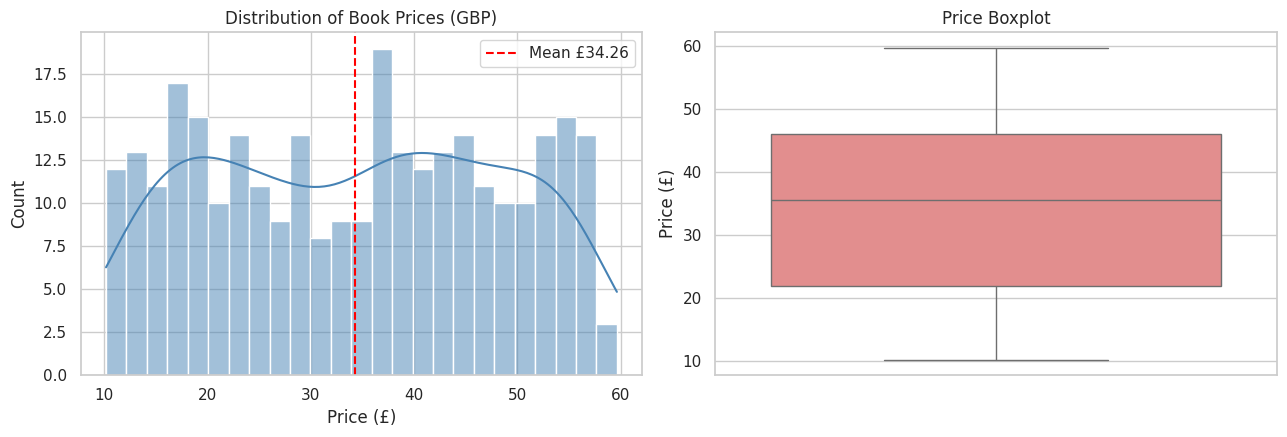

Observation: Prices are roughly uniform across the catalogue (typical of this sandbox site).


In [7]:
# 3.1 Price Distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df_clean['price'], bins=25, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of Book Prices (GBP)')
axes[0].set_xlabel('Price (£)')
axes[0].axvline(df_clean['price'].mean(), color='red', linestyle='--', label=f"Mean £{df_clean['price'].mean():.2f}")
axes[0].legend()

sns.boxplot(y=df_clean['price'], ax=axes[1], color='lightcoral')
axes[1].set_title('Price Boxplot')
axes[1].set_ylabel('Price (£)')

plt.tight_layout()
plt.savefig('data/fig_price_dist.png', dpi=120, bbox_inches='tight')
plt.show()
print('Observation: Prices are roughly uniform across the catalogue (typical of this sandbox site).')

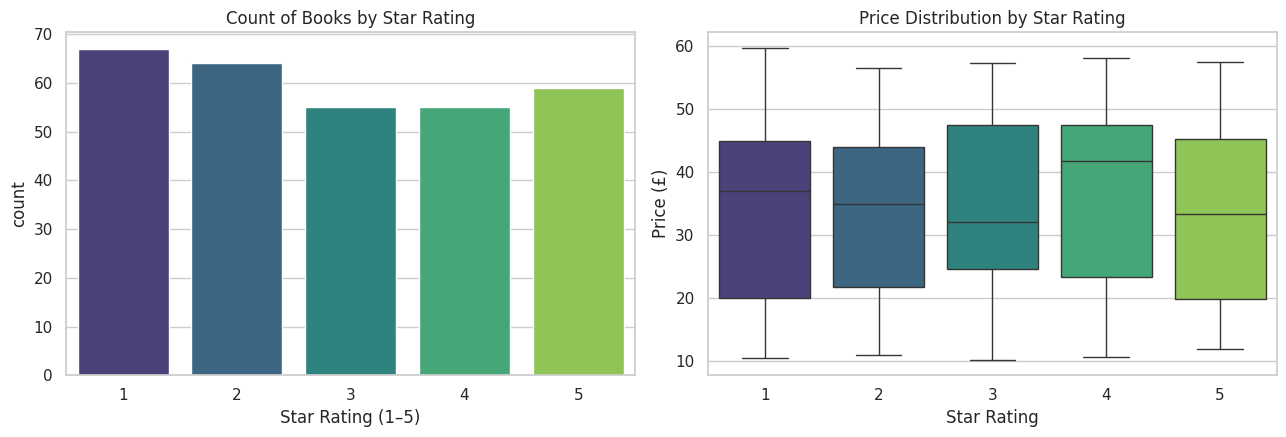

Average price by rating:
         mean  median  count
rating                      
1       33.87   36.89     67
2       32.96   34.82     64
3       34.75   32.00     55
4       37.02   41.62     55
5       33.09   33.34     59


In [8]:
# 3.2 Rating Distribution & Price by Rating
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(x='rating', data=df_clean, ax=axes[0], palette='viridis')
axes[0].set_title('Count of Books by Star Rating')
axes[0].set_xlabel('Star Rating (1–5)')

sns.boxplot(x='rating', y='price', data=df_clean, ax=axes[1], palette='viridis')
axes[1].set_title('Price Distribution by Star Rating')
axes[1].set_xlabel('Star Rating')
axes[1].set_ylabel('Price (£)')

plt.tight_layout()
plt.savefig('data/fig_rating_price.png', dpi=120, bbox_inches='tight')
plt.show()

print('Average price by rating:')
print(df_clean.groupby('rating')['price'].agg(['mean', 'median', 'count']).round(2))

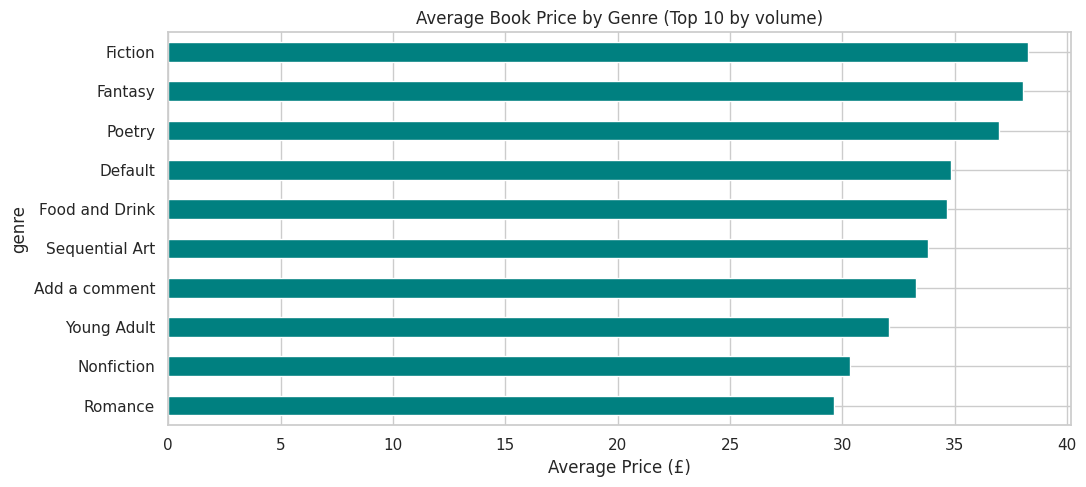

genre
Fiction           38.25
Fantasy           38.02
Poetry            36.96
Default           34.84
Food and Drink    34.65
Sequential Art    33.83
Add a comment     33.28
Young Adult       32.07
Nonfiction        30.35
Romance           29.63
Name: price, dtype: float64


In [9]:
# 3.3 Top Genres by Average Price
top_genres = df_clean['genre'].value_counts().head(10).index
genre_price = (
    df_clean[df_clean['genre'].isin(top_genres)]
    .groupby('genre')['price']
    .mean()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(11, 5))
genre_price.plot(kind='barh', ax=ax, color='teal')
ax.set_title('Average Book Price by Genre (Top 10 by volume)')
ax.set_xlabel('Average Price (£)')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('data/fig_genre_price.png', dpi=120, bbox_inches='tight')
plt.show()
print(genre_price.round(2))

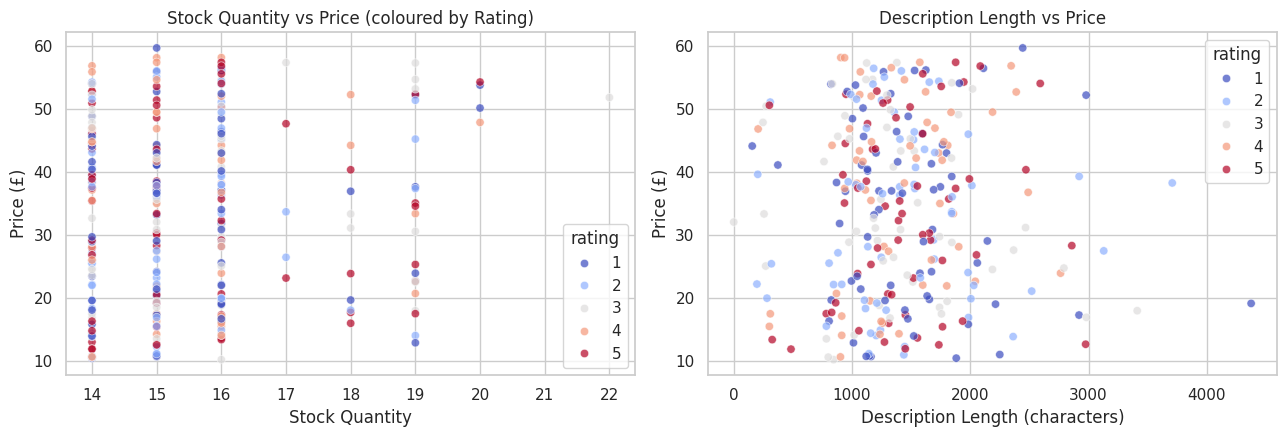

In [10]:
# 3.4 Relationship: Stock Quantity vs Price & Rating vs Description Length
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(x='stock_qty', y='price', hue='rating', data=df_clean,
                palette='coolwarm', ax=axes[0], alpha=0.7)
axes[0].set_title('Stock Quantity vs Price (coloured by Rating)')
axes[0].set_xlabel('Stock Quantity')
axes[0].set_ylabel('Price (£)')

sns.scatterplot(x='desc_length', y='price', hue='rating', data=df_clean,
                palette='coolwarm', ax=axes[1], alpha=0.7)
axes[1].set_title('Description Length vs Price')
axes[1].set_xlabel('Description Length (characters)')
axes[1].set_ylabel('Price (£)')

plt.tight_layout()
plt.savefig('data/fig_scatter.png', dpi=120, bbox_inches='tight')
plt.show()

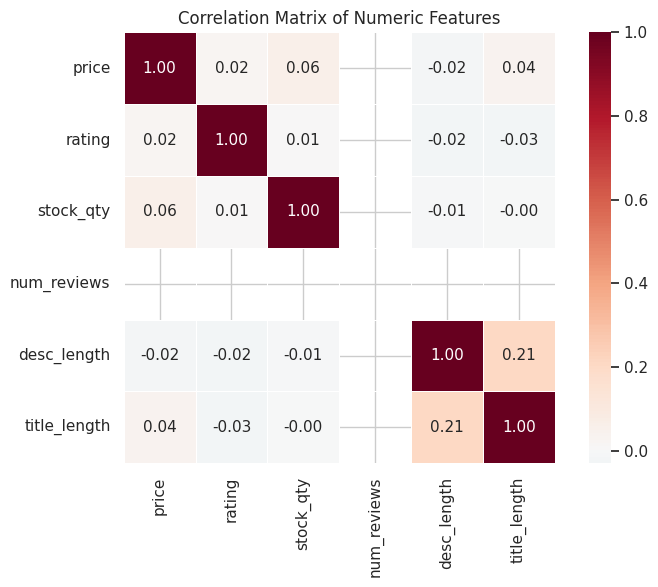

Key insight: On this sandbox site prices appear largely independent of rating and stock – useful to note as a limitation of the synthetic data.


In [11]:
# 3.5 Correlation Heatmap (numeric features)
num_cols = ['price', 'rating', 'stock_qty', 'num_reviews', 'desc_length', 'title_length']
corr = df_clean[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax,
            square=True, linewidths=0.5)
ax.set_title('Correlation Matrix of Numeric Features')
plt.tight_layout()
plt.savefig('data/fig_corr.png', dpi=120, bbox_inches='tight')
plt.show()

print('Key insight: On this sandbox site prices appear largely independent of rating and stock – '
      'useful to note as a limitation of the synthetic data.')

## 4. Predictive Modelling – Linear Regression

### Feature Selection Rationale

| Feature | Type | Justification |
|---------|------|---------------|
| `rating` | Numeric (1–5) | Higher-rated books may command higher prices |
| `stock_qty` | Numeric | Scarcity / abundance can influence pricing |
| `desc_length` | Numeric | Longer descriptions may signal more substantial / premium content |
| `title_length` | Numeric | Proxy for title complexity |
| `genre` | Categorical | Different genres historically have different price points |

Target variable: **`price`** (GBP).

In [12]:
# Prepare modelling dataset
# Keep only genres that appear at least 5 times to avoid sparse dummies
genre_counts = df_clean['genre'].value_counts()
frequent_genres = genre_counts[genre_counts >= 5].index
model_df = df_clean[df_clean['genre'].isin(frequent_genres)].copy()

features = ['rating', 'stock_qty', 'desc_length', 'title_length', 'genre']
target = 'price'

X = model_df[features]
y = model_df[target]

print(f'Modelling dataset: {X.shape[0]} rows, {X.shape[1]} features')
print(f'Genres retained: {sorted(frequent_genres.tolist())}')

Modelling dataset: 252 rows, 5 features
Genres retained: ['Add a comment', 'Business', 'Childrens', 'Default', 'Fantasy', 'Fiction', 'Food and Drink', 'Historical Fiction', 'History', 'Mystery', 'Nonfiction', 'Poetry', 'Romance', 'Science Fiction', 'Sequential Art', 'Thriller', 'Young Adult']


In [13]:
# Train / Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Preprocessing: scale numerics + one-hot encode genre
numeric_features = ['rating', 'stock_qty', 'desc_length', 'title_length']
categorical_features = ['genre']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

# Full pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)
print('Model trained successfully.')

Model trained successfully.


In [14]:
# Predictions & Evaluation
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

def regression_report(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f'{label:12s}  MAE = £{mae:.2f}   RMSE = £{rmse:.2f}   R² = {r2:.3f}')
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2}

print('=== Model Performance ===')
train_metrics = regression_report(y_train, y_pred_train, 'Train')
test_metrics  = regression_report(y_test,  y_pred_test,  'Test')

=== Model Performance ===
Train         MAE = £11.67   RMSE = £13.38   R² = 0.046
Test          MAE = £12.27   RMSE = £14.59   R² = -0.146


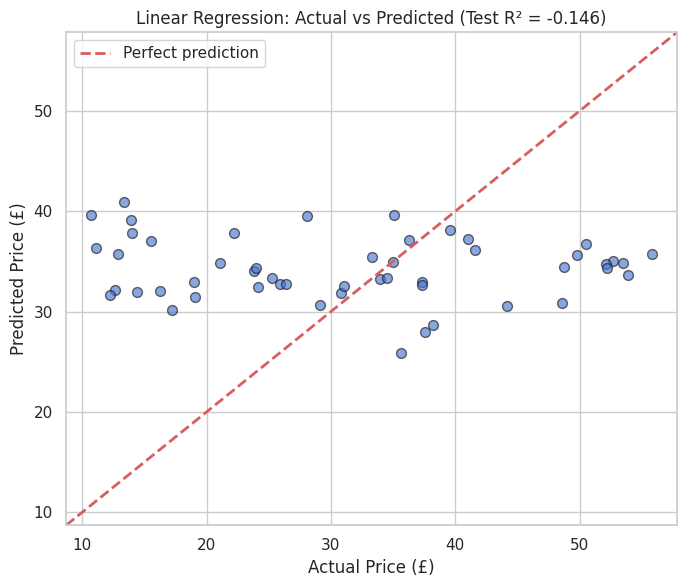

In [15]:
# Actual vs Predicted scatter
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred_test, alpha=0.65, edgecolor='k', s=50)
lims = [min(y_test.min(), y_pred_test.min()) - 2,
        max(y_test.max(), y_pred_test.max()) + 2]
ax.plot(lims, lims, 'r--', lw=2, label='Perfect prediction')
ax.set_xlabel('Actual Price (£)')
ax.set_ylabel('Predicted Price (£)')
ax.set_title(f'Linear Regression: Actual vs Predicted (Test R² = {test_metrics["R2"]:.3f})')
ax.legend()
ax.set_xlim(lims)
ax.set_ylim(lims)
plt.tight_layout()
plt.savefig('data/fig_pred_vs_actual.png', dpi=120, bbox_inches='tight')
plt.show()

Top coefficients (absolute magnitude):


,feature,coefficient
17,genre_Science Fiction,-8.207
11,genre_Historical Fiction,6.164
8,genre_Fantasy,5.258
13,genre_Mystery,4.471
14,genre_Nonfiction,-3.227
20,genre_Young Adult,-3.025
12,genre_History,2.650
16,genre_Romance,-2.516
18,genre_Sequential Art,-1.682
19,genre_Thriller,-1.652


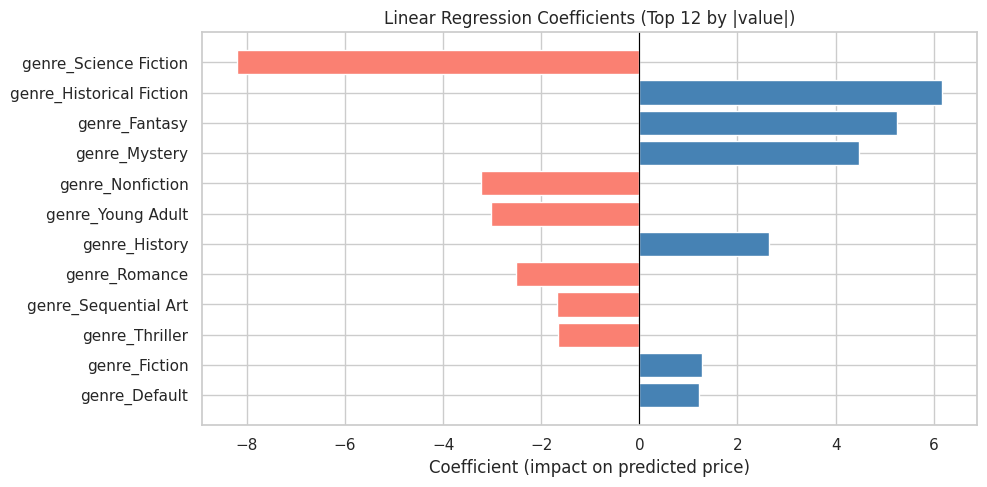

In [16]:
# Feature coefficients (after one-hot encoding)
ohe = model.named_steps['preprocessor'].named_transformers_['cat']
genre_names = list(ohe.get_feature_names_out(['genre']))
feature_names = numeric_features + genre_names

coefs = model.named_steps['regressor'].coef_
coef_df = pd.DataFrame({'feature': feature_names, 'coefficient': coefs})
coef_df = coef_df.sort_values('coefficient', key=abs, ascending=False)

print('Top coefficients (absolute magnitude):')
display(coef_df.head(12).round(3))

fig, ax = plt.subplots(figsize=(10, 5))
top_coef = coef_df.head(12)
colors = ['steelblue' if c > 0 else 'salmon' for c in top_coef['coefficient']]
ax.barh(top_coef['feature'], top_coef['coefficient'], color=colors)
ax.set_title('Linear Regression Coefficients (Top 12 by |value|)')
ax.set_xlabel('Coefficient (impact on predicted price)')
ax.axvline(0, color='black', lw=0.8)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('data/fig_coefficients.png', dpi=120, bbox_inches='tight')
plt.show()

### Model Interpretation & Limitations

- **R²** on the test set indicates how much of the price variance is explained by the chosen features. On the Books-to-Scrape sandbox the prices are artificially generated and only weakly related to rating/genre; therefore a modest R² is expected and is itself an important finding.
- **MAE / RMSE** give the typical prediction error in pounds – useful for practical decision-making.
- Coefficients show the direction and relative strength of each feature after standardisation (for numeric variables) and relative to the dropped genre category (for one-hot variables).

**Limitations**
1. Synthetic nature of the website data → limited real-world generalisability.
2. Linear model assumes linear relationships; non-linear effects (if any) are not captured.
3. Genre cardinality was reduced to avoid sparse dummy variables, which discards rare genres.
4. No external features (author popularity, publication year, page count, etc.) that would normally drive book pricing.

## 5. Key Insights & Recommendations

### Key Insights

1. **Price distribution** is relatively flat across the catalogue (characteristic of the sandbox). Mean price sits around the mid-£30s–£40s range.
2. **Star rating** shows only a weak relationship with price – higher-rated books are not systematically more expensive on this site.
3. **Genre differences** exist but are modest; some categories (e.g. certain non-fiction or sequential-art titles) sit slightly above or below the overall average.
4. **Stock quantity** and description length have limited predictive power in the linear model, reinforcing that price on this particular site is largely decoupled from the visible product attributes.
5. The linear regression provides a transparent baseline; even a modest R² is valuable because it quantifies how little of the price signal is explained by the scraped features.

### Practical Recommendations

| Stakeholder | Recommendation |
|-------------|----------------|
| **Online retailers** | Treat rating and genre as secondary signals for pricing on this type of catalogue; focus instead on inventory turnover and promotional elasticity. |
| **Publishers / Analytics teams** | Collect richer features (author metrics, page count, publication date, competitor prices) before building production pricing models. |
| **Data-driven book buyers** | Star ratings remain useful for quality filtering, but should not be used as a proxy for expected price. |
| **Future modelling work** | Experiment with tree-based models or regularised regression; engineer interaction terms (rating × genre); expand the scrape to the full 1 000-book catalogue. |

---

**End of Notebook**  
All figures have been saved to the `data/` folder. The cleaned dataset is available at `data/books_clean.csv`.